# **3 Листок**

**3.1** (Задача о равномерном спуске) Найти такую кривую, что тяжёлая точка под действием силы тяжести равномерно опускается по этой кривой ($v_y = \text{const} = -v_0 < 0$).
1) Вывести дифференциальное уравнение и найти его аналитическое решение $y = f(x)$;
2) Построить статический график найденной кривой;
3) Создать анимацию спуска точки с постоянной вертикальной скоростью.

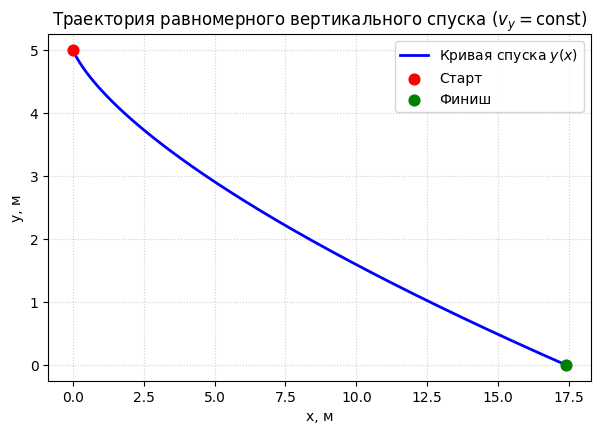

KeyboardInterrupt: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, Math, HTML

# 1. Параметры задачи
g = 9.81
v0 = 2.0  # постоянная вертикальная скорость спуска |vy|
y0 = 5.0  # начальная высота
t_max = y0 / v0

# 2. Аналитическое решение: полукубическая парабола y = f(x)
# x(t) = ( (v0^2 + 2*g*v0*t)**(1.5) - v0^3 ) / (3 * g * v0)
# y(t) = y0 - v0 * t
t_vals = np.linspace(0, t_max, 300)
x_vals = ((v0**2 + 2 * g * v0 * t_vals)**1.5 - v0**3) / (3 * g * v0)
y_vals = y0 - v0 * t_vals

# 3. Статическая визуализация траектории
plt.figure(figsize=(7, 4.5))
plt.plot(x_vals, y_vals, 'b-', lw=2, label=r'Кривая спуска $y(x)$')
plt.scatter([x_vals[0]], [y_vals[0]], color='red', s=60, zorder=5, label='Старт')
plt.scatter([x_vals[-1]], [y_vals[-1]], color='green', s=60, zorder=5, label='Финиш')
plt.title(r'Траектория равномерного вертикального спуска ($v_y = \mathrm{const}$)')
plt.xlabel('x, м')
plt.ylabel('y, м')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.savefig('descent_curve.png', dpi=150)
plt.show()

# 4. Анимация движения материальной точки
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x_vals, y_vals, 'b--', alpha=0.5)
point, = ax.plot([], [], 'ro', ms=8)
time_text = ax.text(0.05, 0.9, '', transform=ax.transAxes)
ax.set_xlim(-0.5, x_vals[-1] + 1)
ax.set_ylim(-0.5, y0 + 0.5)
ax.grid(True, linestyle=':')

def init():
    point.set_data([], [])
    time_text.set_text('')
    return point, time_text

def update(frame):
    point.set_data([x_vals[frame]], [y_vals[frame]])
    time_text.set_text(f't = {t_vals[frame]:.2f} c, vy = -{v0:.1f} м/с')
    return point, time_text

anim = FuncAnimation(fig, update, frames=len(t_vals), init_func=init, blit=True, interval=30)
plt.close(fig)
display(HTML(anim.to_jshtml()))

**3.2** (Задача о бильярде в прямоугольнике) Изучение движения материальной точки в прямоугольнике со сторонами $a$ и $b$ с упругими отражениями от границ (периодические и эргодические траектории, метод развёртки).

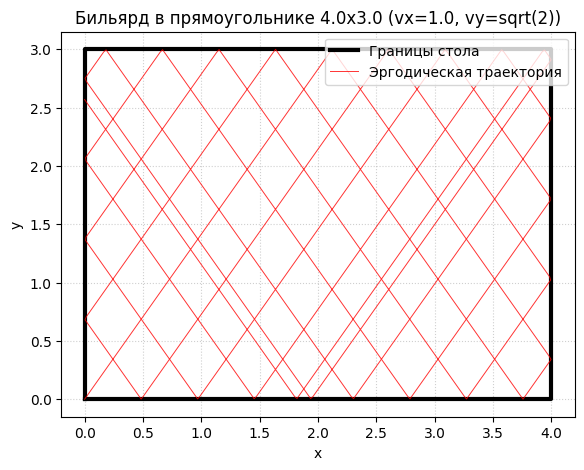

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

# 1. Параметры бильярдного стола и движения
a, b = 4.0, 3.0
vx, vy = 1.0, np.sqrt(2)  # иррациональное отношение скоростей -> эргодическая траектория
t = np.linspace(0, 40, 2000)

# 2. Метод развертки: отражение через периодическую функцию треугольной волны
def unfold(val, length):
    mod = val % (2 * length)
    return np.where(mod <= length, mod, 2 * length - mod)

x_billiard = unfold(vx * t, a)
y_billiard = unfold(vy * t, b)

# 3. Статическая визуализация
plt.figure(figsize=(7, 5))
plt.plot([0, a, a, 0, 0], [0, 0, b, b, 0], 'k-', lw=3, label='Границы стола')
plt.plot(x_billiard, y_billiard, 'r-', lw=0.7, alpha=0.8, label='Эргодическая траектория')
plt.title(f'Бильярд в прямоугольнике {a}x{b} (vx={vx}, vy=sqrt(2))')
plt.xlabel('x')
plt.ylabel('y')
plt.gca().set_aspect('equal')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.savefig('billiard.png', dpi=150)
plt.show()

# 4. Анимация движения шара
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, a, a, 0, 0], [0, 0, b, b, 0], 'k-', lw=3)
trail, = ax.plot([], [], 'r-', lw=0.8, alpha=0.6)
ball, = ax.plot([], [], 'bo', ms=9)
ax.set_xlim(-0.2, a + 0.2)
ax.set_ylim(-0.2, b + 0.2)
ax.set_aspect('equal')

def update(frame):
    step = frame * 4
    trail.set_data(x_billiard[:step], y_billiard[:step])
    ball.set_data([x_billiard[step]], [y_billiard[step]])
    return trail, ball

anim_billiard = FuncAnimation(fig, update, frames=len(t)//4, interval=25, blit=True)
plt.close(fig)
display(HTML(anim_billiard.to_jshtml()))

**3.3** (Задача о цепной линии) Исследовать форму равновесия однородной тяжёлой нерастяжимой нити, подвешенной за два конца: $y = a \cosh(x/a)$.

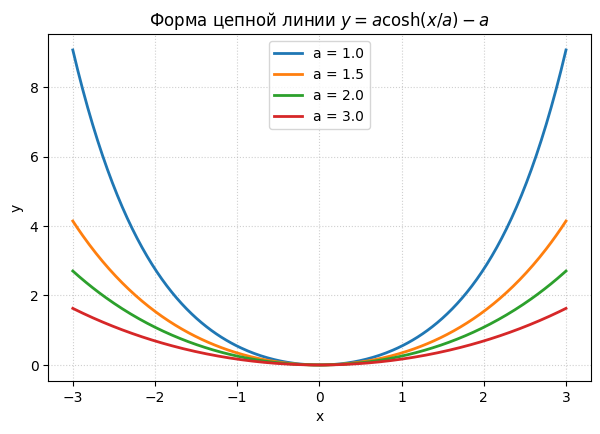

KeyboardInterrupt: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

# 1. Расчет цепной линии для различных значений параметра a = T0 / (rho * g)
x = np.linspace(-3, 3, 300)
a_values = [1.0, 1.5, 2.0, 3.0]

# 2. Статическая визуализация
plt.figure(figsize=(7, 4.5))
for a in a_values:
    y = a * np.cosh(x / a) - a  # смещаем так, чтобы вершина была в нуле
    plt.plot(x, y, lw=2, label=f'a = {a}')

plt.title(r'Форма цепной линии $y = a\cosh(x/a) - a$')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.savefig('catenary.png', dpi=150)
plt.show()

# 3. Анимация провисания нити при изменении параметра натяжения a
fig, ax = plt.subplots(figsize=(7, 4.5))
line, = ax.plot([], [], 'b-', lw=2.5)
ax.set_xlim(-3, 3)
ax.set_ylim(-0.2, 5)
ax.grid(True, linestyle=':')
ax.set_title('Изменение формы цепи при ослаблении натяжения')

a_frames = np.linspace(3.0, 0.8, 60)

def update(frame):
    a = a_frames[frame]
    y = a * np.cosh(x / a) - a
    line.set_data(x, y)
    return line,

anim_catenary = FuncAnimation(fig, update, frames=len(a_frames), interval=50, blit=True)
plt.close(fig)
display(HTML(anim_catenary.to_jshtml()))

**3.4** (Задача о таутохроне) Исследовать свойство изохронности циклоиды: время скатывания точки по перевёрнутой циклоиде до нижней точки не зависит от начальной высоты.


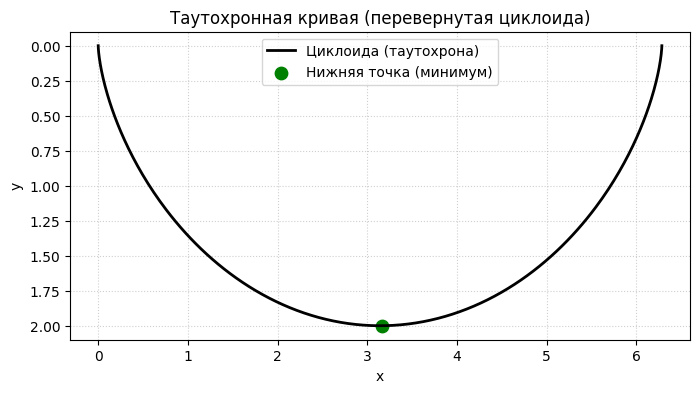

KeyboardInterrupt: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

# 1. Параметрическое задание перевернутой циклоиды
R, g = 1.0, 9.81
theta = np.linspace(0, 2 * np.pi, 300)
x_cyc = R * (theta - np.sin(theta))
y_cyc = R * (1 - np.cos(theta))

# 2. Статическая визуализация кривой
plt.figure(figsize=(8, 4))
plt.plot(x_cyc, y_cyc, 'k-', lw=2, label='Циклоида (таутохрона)')
plt.gca().invert_yaxis()  # нижняя точка траектории внизу
plt.scatter([x_cyc[len(x_cyc)//2]], [y_cyc[len(y_cyc)//2]], color='green', s=80, label='Нижняя точка (минимум)')
plt.title('Таутохронная кривая (перевернутая циклоида)')
plt.xlabel('x')
plt.ylabel('y')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.savefig('tautochrone.png', dpi=150)
plt.show()

# 3. Анимация одновременного скатывания шариков с разных начальных высот
# Уравнение движения вдоль дуги циклоиды: d^2(s)/dt^2 + (g / 4R) * s = 0 (гармонический осциллятор!)
omega = np.sqrt(g / (4 * R))
t_arr = np.linspace(0, np.pi / (2 * omega), 80)

# Три начальных угла отклонения
theta0_list = [np.pi * 0.4, np.pi * 0.7, np.pi * 0.95]
colors = ['red', 'blue', 'orange']

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x_cyc, y_cyc, 'k-', lw=1.5)
ax.invert_yaxis()
balls = [ax.plot([], [], 'o', color=col, ms=9, label=f'Шарик {i+1}')[0] for i, col in enumerate(colors)]
ax.legend()
ax.grid(True, linestyle=':')
ax.set_title('Изохронный спуск: одновременное прибытие в нижнюю точку')

def update(frame):
    t = t_arr[frame]
    for i, th0 in enumerate(theta0_list):
        # s(t) = s0 * cos(omega * t), для циклоиды s = 4R * cos(theta/2)
        th = np.pi - 2 * np.arcsin(np.sin(th0 / 2) * np.cos(omega * t))
        bx = R * (th - np.sin(th))
        by = R * (1 - np.cos(th))
        balls[i].set_data([bx], [by])
    return balls

anim_tauto = FuncAnimation(fig, update, frames=len(t_arr), interval=40, blit=True)
plt.close(fig)
display(HTML(anim_tauto.to_jshtml()))

**3.5** (Движение математического маятника) Исследовать нелинейные колебания математического маятника $\ddot{\theta} + \omega_0^2 \sin\theta = 0$, построить фазовый портрет с сепаратрисой и анимацию.


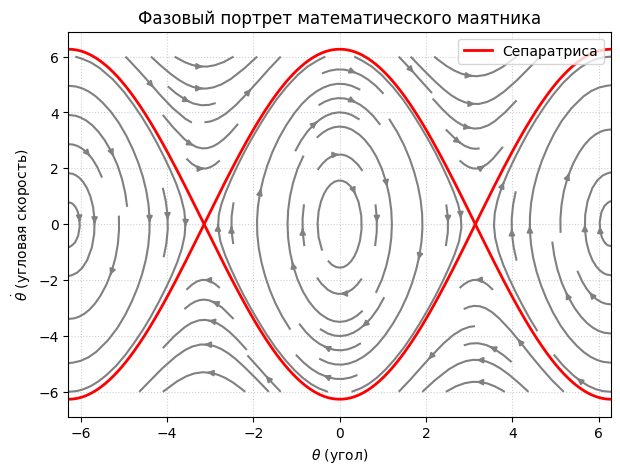

: 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML

# 1. Уравнение движения маятника: d/dt [theta, omega] = [omega, -g/L * sin(theta)]
g, L = 9.81, 1.0
omega0_sq = g / L

def pendulum_deriv(state, t):
    theta, omega = state
    return [omega, -omega0_sq * np.sin(theta)]

# 2. Фазовый портрет (статический)
plt.figure(figsize=(7, 5))
th_grid, om_grid = np.meshgrid(np.linspace(-2*np.pi, 2*np.pi, 20), np.linspace(-6, 6, 20))
d_th = om_grid
d_om = -omega0_sq * np.sin(th_grid)
plt.streamplot(th_grid, om_grid, d_th, d_om, color='gray', density=0.8, arrowsize=0.8)

# Построение сепаратрисы E = 2 * omega0^2 (разделяющей колебания и вращения)
th_dense = np.linspace(-2*np.pi, 2*np.pi, 400)
sep_omega = 2 * np.sqrt(omega0_sq) * np.cos(th_dense / 2)
plt.plot(th_dense, sep_omega, 'r-', lw=2, label='Сепаратриса')
plt.plot(th_dense, -sep_omega, 'r-', lw=2)

plt.title('Фазовый портрет математического маятника')
plt.xlabel(r'$\theta$ (угол)')
plt.ylabel(r'$\dot{\theta}$ (угловая скорость)')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.savefig('pendulum_phase.png', dpi=150)
plt.show()

# 3. Анимация движения маятника в пространстве
t_sim = np.linspace(0, 5, 200)
theta_sol = odeint(pendulum_deriv, [np.pi * 0.7, 0.0], t_sim)[:, 0]
x_pend = L * np.sin(theta_sol)
y_pend = -L * np.cos(theta_sol)

fig, ax = plt.subplots(figsize=(5, 5))
ax.set_xlim(-1.2*L, 1.2*L)
ax.set_ylim(-1.2*L, 0.2*L)
ax.set_aspect('equal')
ax.grid(True, linestyle=':')
ax.plot(0, 0, 'ks', ms=6)  # точка подвеса
rod, = ax.plot([], [], 'k-', lw=2)
bob, = ax.plot([], [], 'ro', ms=14)

def update(frame):
    rod.set_data([0, x_pend[frame]], [0, y_pend[frame]])
    bob.set_data([x_pend[frame]], [y_pend[frame]])
    return rod, bob

anim_pendulum = FuncAnimation(fig, update, frames=len(t_sim), interval=25, blit=True)
plt.close(fig)
display(HTML(anim_pendulum.to_jshtml()))